# B3 Parameter Grid Search
6-dimension grid across BOVA11 and PETR4 with train/holdout split. Train ends pre-COVID (Mar 2020 crash excluded). Holdout = 2020-04 to 2025-12.

Backtests run with **cash_investment_mode="risk_free" + yield=0%** so that `sharpe`, `total_return`, `max_drawdown` reflect the pure strangle P&L — no underlying B&H contamination.

In [1]:
%matplotlib inline
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if (Path.cwd().name == "research") else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
sys.path.insert(0, str(ROOT / "src"))
from grid_search import run_grid, enumerate_grid, GRID_DIMS

OUT_DIR = ROOT / "data" / "B3"
RESULTS_PATH = OUT_DIR / "grid_search_results_strangle.parquet"

In [2]:
GRID = {
    "target_delta": [0.20, 0.25, 0.30],
    "dte_max": [21, 30, 45],
    "profit_target_pct": [0.25, 0.50, 0.75],
    "manage_at_dte": [10, 14, 21],
    "vix_filter": [25, 30, 35, "OFF"],
    "defensive_leg_roll": [True, False],
}
combos = enumerate_grid(GRID)
print(f"Valid combos per (market, period): {len(combos)}")

Grid: 648 raw combos, 504 after validity filter (144 dropped)
Valid combos per (market, period): 504


In [3]:
RUNS = [
    ("train", "bova11", "2017-01-01", "2019-12-31"),
    ("holdout", "bova11", "2020-04-01", "2025-12-01"),
    ("train", "petr4", "2011-01-01", "2019-12-31"),
    ("holdout", "petr4", "2020-04-01", "2025-12-01"),
]
for r in RUNS:
    print(r)

('train', 'bova11', '2017-01-01', '2019-12-31')
('holdout', 'bova11', '2020-04-01', '2025-12-01')
('train', 'petr4', '2011-01-01', '2019-12-31')
('holdout', 'petr4', '2020-04-01', '2025-12-01')


In [4]:
df = run_grid(GRID, RUNS, n_workers=-1, output_path=RESULTS_PATH)
print(f"Saved {len(df)} rows to {RESULTS_PATH}")

Grid: 648 raw combos, 504 after validity filter (144 dropped)
Dispatching 504 tasks for bova11 (train)...


bova11-train:   0%|          | 0/504 [00:00<?, ?it/s]

MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=bova11, underlying_filter=True)MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=bova11, underlying_filter=True)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=bova11, underlying_filter=True)MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=bova11, underlying_filter=True)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=bova11, underlying_filter=True)

MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=bova11, underlying_filter=True)

MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=bova11, underlying_filter=True)
Market

Simulating portfolio:  28%|██▊       | 208/739 [00:00<00:00, 2073.45day/s]

MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=bova11, underlying_filter=True)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=bova11, underlying_filter=True)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=bova11, underlying_filter=True)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=bova11, underlying_filter=True)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=bova11, underlying_filter=True)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=bova11, underlying_filter=True)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=bova11, underlying_filter=True)
Market

...

MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=petr4, underlying_filter=True)


Simulating portfolio:   0%|          | 0/1414 [00:00<?, ?day/s]582.04day/s]

MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=petr4, underlying_filter=True)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options.db (market=petr4, underlying_filter=True)


petr4-holdout: 100%|██████████| 504/504 [00:59<00:00,  8.44it/s]


Checkpoint saved: 2016 rows → /Users/oliversteiner/Documents/code/options-backtest/data/B3/grid_search_results_strangle.parquet
Summary: 2016 runs total — 0 errors, 86 with n_trades < 50, 0 invalid (manage_at_dte >= dte_min)
Saved 2016 rows to /Users/oliversteiner/Documents/code/options-backtest/data/B3/grid_search_results_strangle.parquet


In [5]:
df = pd.read_parquet(RESULTS_PATH)
print(df.shape)
df.head()

(2016, 22)


,target_delta,dte_max,profit_target_pct,manage_at_dte,vix_filter,defensive_leg_roll,market,period_label,start_date,end_date,...,annualized_return,sharpe,max_drawdown,calmar,win_rate,underlying_return,underlying_sharpe,alpha_vs_bh,alpha_sharpe,error
0,0.2,21,0.25,10,25,True,bova11,train,2017-01-01,2019-12-31,...,-0.000698,-3.387166,-0.021149,-0.033027,0.819672,0.930071,0.838801,-0.932162,-1.215868,None
1,0.2,21,0.25,10,25,False,bova11,train,2017-01-01,2019-12-31,...,0.010375,-3.737121,-0.008072,1.285240,0.885246,0.930071,0.838801,-0.898675,-1.152866,None
2,0.2,21,0.25,10,30,True,bova11,train,2017-01-01,2019-12-31,...,0.002374,-2.997255,-0.021862,0.108581,0.867647,0.930071,0.838801,-0.922944,-1.202935,None
3,0.2,21,0.25,10,30,False,bova11,train,2017-01-01,2019-12-31,...,0.013324,-3.438815,-0.006453,2.064937,0.926471,0.930071,0.838801,-0.889629,-1.140265,None
4,0.2,21,0.25,10,35,True,bova11,train,2017-01-01,2019-12-31,...,0.003150,-2.930209,-0.021862,0.144088,0.871429,0.930071,0.838801,-0.920606,-1.199107,None


In [6]:
print("Total rows:", len(df))
print("By market \u00d7 period:")
print(df.groupby(["market", "period_label"]).size())
print("\nFailures:", (df["error"].notna()).sum())
print("Underpowered (n_trades < 50):", (df["n_trades"] < 50).sum())

clean = df[df["error"].isna()]
print("\n=== Strangle Sharpe (pure options, no B&H) ===")
print(
    clean.groupby(["market", "period_label"])["sharpe"].describe()[
        ["mean", "std", "min", "max"]
    ]
)

print("\n=== Alpha Sharpe (residual vs B&H) ===")
print(
    clean.groupby(["market", "period_label"])["alpha_sharpe"].describe()[
        ["mean", "std", "min", "max"]
    ]
)

print("\n=== Alpha vs B&H (return delta) ===")
print(
    clean.groupby(["market", "period_label"])["alpha_vs_bh"].describe()[
        ["mean", "std", "min", "max"]
    ]
)

if (df["error"].notna()).sum() > 0:
    print(f"\nWARNING: {df['error'].notna().sum()} failed rows")
    failures = df[df["error"].notna()]
    for _, r in failures.iterrows():
        print(
            f"  [{r['market']}/{r['period_label']}]"
            f" vix={r['vix_filter']} d={r['target_delta']}"
            f" dte={r['dte_max']}: {str(r['error'])[:200]}"
        )

Total rows: 2016
By market × period:
market  period_label
bova11  holdout         504
        train           504
petr4   holdout         504
        train           504
dtype: int64

Failures: 0
Underpowered (n_trades < 50): 86

=== Strangle Sharpe (pure options, no B&H) ===
                         mean       std        min       max
market period_label                                         
bova11 holdout      -1.092131  0.555667  -3.297247 -0.093577
       train        -0.227315  0.732660  -4.284169  0.466497
petr4  holdout      -3.189815  2.896723 -20.581686  0.416393
       train        -5.067724  3.364908 -19.398029 -0.703341

=== Alpha Sharpe (residual vs B&H) ===
                         mean       std       min       max
market period_label                                        
bova11 holdout      -0.892794  0.086759 -1.113857 -0.522305
       train        -0.885788  0.212054 -1.227817 -0.292227
petr4  holdout      -0.592799  0.057935 -0.736956  0.411857
       train     

## Verification

Checks from the plan (docs/B3_GRID_SEARCH_PLAN.md:241-247).

In [7]:
from grid_search import enumerate_grid, GRID_DIMS, DTE_MIN_BY_DTE_MAX

print("Check 1: self-equivalence — see scripts/grid_search.py output")

invalid = df[
    (df["manage_at_dte"] >= df["dte_max"].map(DTE_MIN_BY_DTE_MAX)) & df["error"].isna()
]
assert len(invalid) == 0, f"{len(invalid)} rows violate manage_at_dte < dte_min!"
print(f"Check 2: validity filter — {len(invalid)} post-run violations (expect 0)")

print("Check 3: n\u003c50 — see sanity checks output above")

for mkt in ["bova11", "petr4"]:
    train = df.query(
        "period_label=='train' and market==@mkt and error.isna()", engine="python"
    )
    hold = df.query(
        "period_label=='holdout' and market==@mkt and error.isna()", engine="python"
    )
    j = train.merge(hold, on=GRID_DIMS, suffixes=("_t", "_h"))
    print(
        f"Check 4: {mkt.upper()} — {len(j)}/{len(train)} train configs matched in holdout"
    )
    if len(j) < len(train):
        print(f"  WARNING: {len(train) - len(j)} train configs missing!")

combos2 = enumerate_grid(GRID)
n_valid = df.groupby(["market", "period_label"]).size().unique()
print(f"Check 5: valid combos = {len(combos2)}, rows per period = {n_valid.tolist()}")
assert all(c == len(combos2) for c in n_valid), "diagonal size mismatch"

Check 1: self-equivalence — see scripts/grid_search.py output
Check 2: validity filter — 0 post-run violations (expect 0)
Check 3: n<50 — see sanity checks output above
Check 4: BOVA11 — 504/504 train configs matched in holdout
Check 4: PETR4 — 504/504 train configs matched in holdout
Grid: 648 raw combos, 504 after validity filter (144 dropped)
Check 5: valid combos = 504, rows per period = [504]


## Heatmap (a) — Sharpe by target_delta × dte_max

Sharpe = pure strangle (risk-free cash, zero yield).

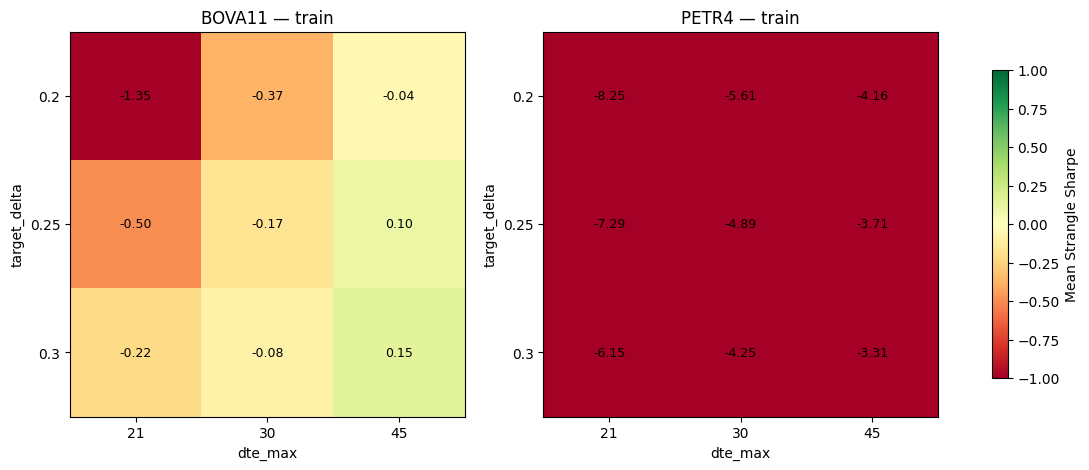

In [8]:
def heatmap(ax, sub, x, y, title, metric="sharpe"):
    pivot = sub.pivot_table(values=metric, index=y, columns=x, aggfunc="mean")
    im = ax.imshow(pivot.values, cmap="RdYlGn", vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns)
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels(pivot.index)
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.set_title(title)
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            v = pivot.values[i, j]
            ax.text(
                j,
                i,
                f"{v:.2f}" if pd.notna(v) else "n/a",
                ha="center",
                va="center",
                color="black",
                fontsize=9,
            )
    return im


fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, mkt in zip(axes, ["bova11", "petr4"]):
    sub = df.query(
        "period_label == 'train' and market == @mkt and error.isna()", engine="python"
    )
    im = heatmap(ax, sub, "dte_max", "target_delta", f"{mkt.upper()} \u2014 train")
fig.colorbar(im, ax=axes, label="Mean Strangle Sharpe", shrink=0.8)
plt.savefig(OUT_DIR / "grid_heatmap_delta_dte.png", dpi=120, bbox_inches="tight")
plt.show()

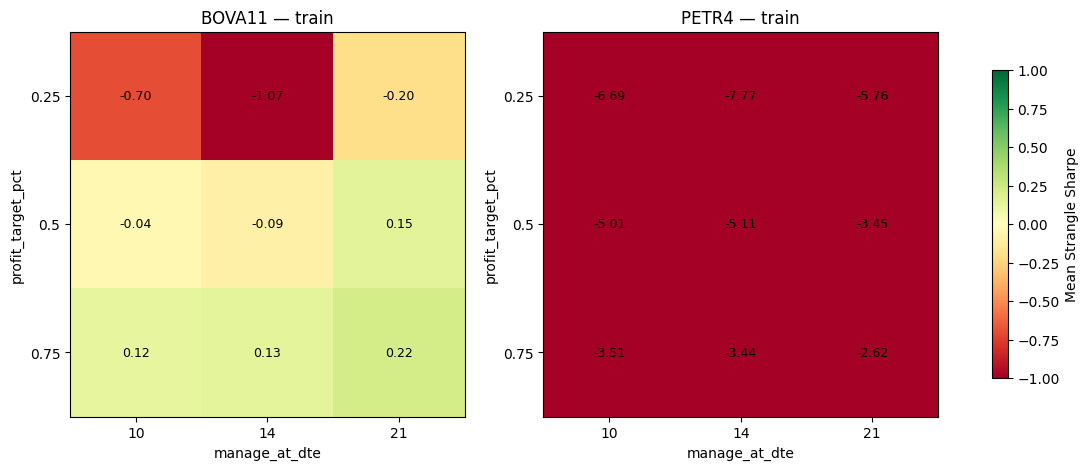

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, mkt in zip(axes, ["bova11", "petr4"]):
    sub = df.query(
        "period_label == 'train' and market == @mkt and error.isna()", engine="python"
    )
    im = heatmap(
        ax, sub, "manage_at_dte", "profit_target_pct", f"{mkt.upper()} \u2014 train"
    )
fig.colorbar(im, ax=axes, label="Mean Strangle Sharpe", shrink=0.8)
plt.savefig(OUT_DIR / "grid_heatmap_profit_manage.png", dpi=120, bbox_inches="tight")
plt.show()

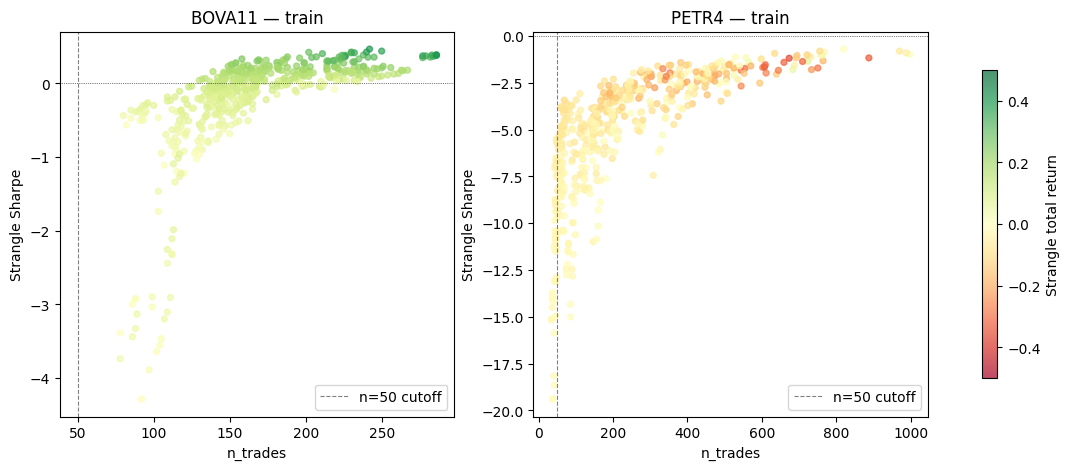

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, mkt in zip(axes, ["bova11", "petr4"]):
    sub = df.query(
        "period_label == 'train' and market == @mkt and error.isna()", engine="python"
    )
    sc = ax.scatter(
        sub["n_trades"],
        sub["sharpe"],
        c=sub["total_return"],
        cmap="RdYlGn",
        vmin=-0.5,
        vmax=0.5,
        s=18,
        alpha=0.7,
    )
    ax.axvline(50, ls="--", c="grey", lw=0.8, label="n=50 cutoff")
    ax.axhline(0, ls=":", c="black", lw=0.5)
    ax.set_xlabel("n_trades")
    ax.set_ylabel("Strangle Sharpe")
    ax.set_title(f"{mkt.upper()} \u2014 train")
    ax.legend(loc="lower right")
fig.colorbar(sc, ax=axes, label="Strangle total return", shrink=0.8)
plt.savefig(OUT_DIR / "grid_scatter_ntrades_sharpe.png", dpi=120, bbox_inches="tight")
plt.show()


=== BOVA11 top-10 by train sharpe (n_trades>=50) ===
  sharpe  alpha_sharpe  alpha_vs_bh  total_return   calmar  n_trades  target_delta  dte_max  profit_target_pct  manage_at_dte vix_filter  defensive_leg_roll
0.466497     -0.433040    -0.536196      0.393876 0.882190       242          0.30       45               0.75             14        OFF               False
0.439233     -0.461736    -0.559583      0.370488 0.846766       250          0.30       30               0.75             14        OFF               False
0.426117     -0.453487    -0.561910      0.368161 0.812825       240          0.30       45               0.75             14         35               False
0.425575     -0.547217    -0.596042      0.334030 0.751867       230          0.25       45               0.75             14        OFF               False
0.423321     -0.682157    -0.647090      0.282981 1.265479       202          0.30       21               0.75             14        OFF               False
0.41

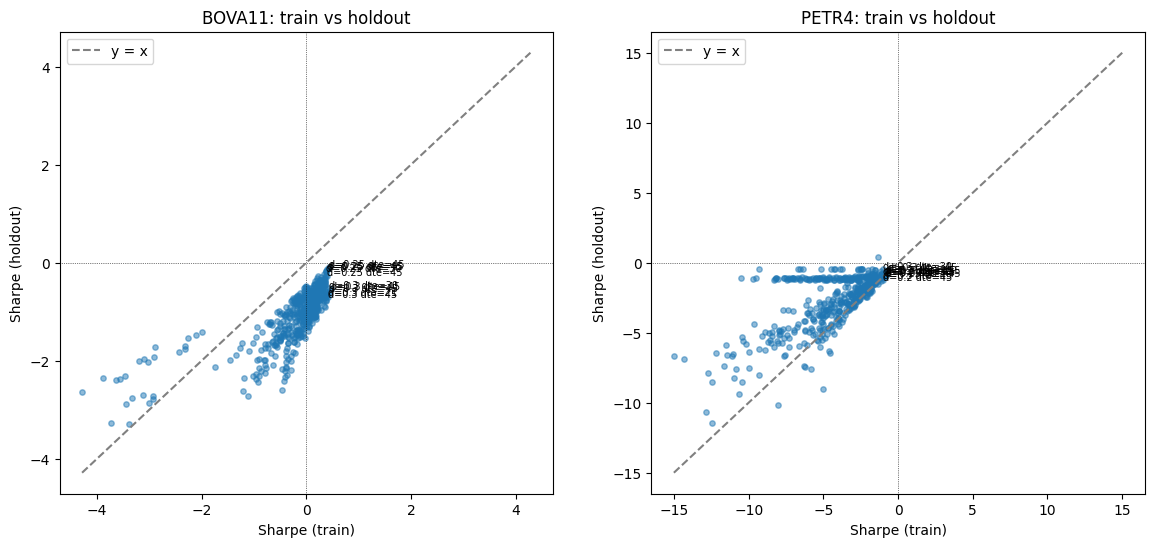

In [11]:
COLS = [
    "sharpe",
    "alpha_sharpe",
    "alpha_vs_bh",
    "total_return",
    "calmar",
    "n_trades",
] + GRID_DIMS

for mkt in ["bova11", "petr4"]:
    print(f"\n=== {mkt.upper()} top-10 by train sharpe (n_trades>=50) ===")
    top = df.query(
        "period_label=='train' and market==@mkt and error.isna() and n_trades>=50",
        engine="python",
    ).nlargest(10, "sharpe")[COLS]
    print(top.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, mkt in zip(axes, ["bova11", "petr4"]):
    train = df.query(
        "period_label=='train' and market==@mkt and error.isna() and n_trades>=50",
        engine="python",
    )
    hold = df.query(
        "period_label=='holdout' and market==@mkt and error.isna() and n_trades>=50",
        engine="python",
    )
    j = train.merge(hold, on=GRID_DIMS, suffixes=("_t", "_h"))
    ax.scatter(j["sharpe_t"], j["sharpe_h"], alpha=0.5, s=15)
    lim = max(abs(j[["sharpe_t", "sharpe_h"]].values).max() if len(j) else 1.0, 1.0)
    ax.plot([-lim, lim], [-lim, lim], ls="--", c="grey", label="y = x")
    ax.axhline(0, ls=":", c="black", lw=0.5)
    ax.axvline(0, ls=":", c="black", lw=0.5)
    top = j.nlargest(10, "sharpe_t")
    for _, r in top.iterrows():
        ax.annotate(
            f"d={r.target_delta} dte={r.dte_max}", (r.sharpe_t, r.sharpe_h), fontsize=7
        )
    ax.set_xlabel("Sharpe (train)")
    ax.set_ylabel("Sharpe (holdout)")
    ax.set_title(f"{mkt.upper()}: train vs holdout")
    ax.legend(loc="upper left")
plt.savefig(OUT_DIR / "grid_train_vs_holdout.png", dpi=120, bbox_inches="tight")
plt.show()

## Conclusions
Fill in based on the charts above:
- Top-cluster signal: are top-10 train configs concentrated or scattered?
- Holdout robustness: do top configs cluster on/above the y=x diagonal?
- Sharpe sign: is any positive strangle Sharpe achievable?
- Alpha vs B&H: does the strangle overlay add risk-adjusted value (positive alpha_sharpe)?
- n<50 coverage: any market×period where most configs are underpowered?